# Reactive (Type-I) AI vs. History-Dependent LSTM vs. Rules for Cybersecurity Digital Twins

**A controlled study of the performance / memory / latency tradeoff of the AI decision layer.**

This notebook implements the pre-implementation experimental design from
`Type_I_AI_Cybersecurity_Digital_Twin_IEEE_Research_Foundation.md` (Models 0/1/2) and extends it with
two study lifts: **Ablation E** (history access without recurrence) and **chain-stage metrics**.

## Decision layers compared (capacity-matched, ~100K parameters)

| Model | Policy | History access | Role |
|---|---|---|---|
| **Rules** | thresholds over current CDT state | none | Model 0 baseline |
| **M1-MLP** | `a_t = pi(s_t)` | none (current state only) | Type-1 reactive |
| **M1-flat** | `a_t = pi(s_{t-k}..s_t)` flattened | window buffer, no recurrence | **Ablation E** |
| **M2-LSTM** | `a_t = pi(s_{t-k}..s_t)` recurrent | window buffer + recurrence | history-dependent |

## Experiments

1. **Synthetic CDT scenarios** (seeded, deterministic): **A** snapshot-deterministic attacks,
   **B** temporally dependent attack chains (recon -> cred -> lateral -> exfil),
   **C** synchronization degradation (stale CDT observations).
2. **Chain-stage metrics** on Scenario B: per-stage recall + chain completeness.
3. **External validity** on real data: CIC-IDS2017 (Friday-Afternoon-DDos flows).
4. **Memory/latency vs. window length k**: where history cost actually comes from.

## Environment (uv)

```bash
uv venv .venv
uv pip install --python .venv/bin/python torch pandas scikit-learn matplotlib psutil ipykernel nbclient nbformat
```

All models train/infer on **CPU** so latency and memory are comparable across models.


## 0. Setup and configuration


In [1]:
import os, sys, time, json, random, pickle, urllib.request, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import torch.nn as nn
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, accuracy_score

print("python", sys.version.split()[0], "| torch", torch.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn ok")
torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

SEEDS = [0, 1, 2]
N_TIMESTEPS = 8000
K = 20
EPOCHS = 25
EPOCHS_REAL = 15
BATCH = 128
LR = 1e-3
N_FEATURES = 16
SYNC_DELAYS = [0, 1, 2, 5, 10]
K_SWEEP = [1, 5, 10, 20, 50]
LAT_ITERS = 200
TRAIN_CAP = 25000
TRAIN_FRAC = 0.7
MODEL_ORDER = ["Rules", "M1-MLP", "M1-flat", "M2-LSTM"]
MODEL_COLORS = {"Rules": "#888888", "M1-MLP": "#1f77b4", "M1-flat": "#2ca02c", "M2-LSTM": "#d62728"}


python 3.14.7 | torch 2.14.1 | numpy 2.5.3 | pandas 3.0.6 | sklearn ok


## 1. Synthetic CDT state generator

Per the paper's CDT state vector, each timestep is an instantaneous 16-dimensional security-posture
observation. **Feature discipline** (paper S XX): all features are *current-state* quantities, no rolling
counts — so the reactive restriction `a_t = pi(s_t)` is honest.

- **Scenario A (snapshot-deterministic):** short attack episodes whose signature is unmistakable in the
  *current* state (+3..8 sigma on 2-3 features). All decision layers should work; Type-1 should match LSTM.
- **Scenario B (temporally dependent):** multi-stage chains **recon -> cred -> lateral -> exfil**, where each
  stage only nudges features by ~1 sigma (snapshot-ambiguous) but the *sequence* is highly visible to any
  model that can average/integrate over a k=20 window. Stage labels 0..4 are kept for chain metrics.
- **Scenario C (sync degradation):** test-time observations are served **stale** (lag d timesteps) —
  the CDT synchronization quality question (H5).


In [2]:
FEATURES = [
    "failed_auth_burst", "auth_success_ratio", "new_external_connections",
    "privileged_ops", "data_out_bytes_norm", "port_diversity", "dns_query_volume",
    "service_error_rate", "process_anomaly_score", "config_changes",
    "lateral_conn_attempts", "endpoint_load", "patch_freshness", "trust_index",
    "session_length_norm", "packet_burst_norm",
]
FI = {n: i for i, n in enumerate(FEATURES)}
assert len(FEATURES) == N_FEATURES

def benign_stream(n, rng):
    F = rng.normal(0.0, 1.0, size=(n, N_FEATURES))
    t = np.arange(n)
    slow = np.sin(2 * np.pi * t / 500.0)
    F[:, FI["failed_auth_burst"]] += 0.6 * slow
    F[:, FI["data_out_bytes_norm"]] += 0.8 * slow
    F[:, FI["dns_query_volume"]] += 0.7 * slow
    F[:, FI["endpoint_load"]] += 0.9 * slow
    walk = np.cumsum(rng.normal(0, 0.05, size=(n, 2)), axis=0)
    walk = (walk - walk.mean(0)) / (walk.std(0) + 1e-8)
    F[:, [FI["patch_freshness"], FI["trust_index"]]] = walk
    return F

PROFILES_A = {
    "brute_force": {"failed_auth_burst": 7.0, "auth_success_ratio": -4.0, "new_external_connections": 2.0},
    "exfil": {"data_out_bytes_norm": 7.5, "new_external_connections": 3.5, "session_length_norm": 3.0},
    "ddos": {"packet_burst_norm": 8.0, "endpoint_load": 6.0, "service_error_rate": 5.0},
}

def scenario_A(n, seed):
    rng = np.random.default_rng(seed)
    F = benign_stream(n, rng)
    labels = np.zeros(n, np.int64)
    stages = np.zeros(n, np.int64)
    names = list(PROFILES_A)
    starts = np.sort(rng.choice(np.arange(30, n - 40), size=max(8, n // 110), replace=False))
    episodes, last = [], -99
    for s in starts:
        if s - last < 12:
            continue
        last = int(s)
        L = int(rng.integers(3, 10))
        prof = PROFILES_A[names[rng.integers(0, 3)]]
        for f, d in prof.items():
            F[s:s + L, FI[f]] += d * rng.uniform(0.85, 1.15)
        labels[s:s + L] = 1
        stages[s:s + L] = 1
        episodes.append((int(s), int(s + L)))
    return F, labels, stages, {"episodes": episodes}

STAGE_ORDER = ["recon", "cred", "lateral", "exfil"]
STAGE_SIG = {
    "recon": {"port_diversity": 1.1, "dns_query_volume": 0.9, "new_external_connections": 0.8},
    "cred": {"failed_auth_burst": 1.0, "auth_success_ratio": -0.9},
    "lateral": {"lateral_conn_attempts": 1.2, "privileged_ops": 0.9},
    "exfil": {"data_out_bytes_norm": 1.3, "session_length_norm": 0.8, "new_external_connections": 0.7},
}
N_CHAINS_TARGET = 45

def scenario_B(n, seed):
    rng = np.random.default_rng(seed)
    F = benign_stream(n, rng)
    labels = np.zeros(n, np.int64)
    stages = np.zeros(n, np.int64)
    chains = []
    # spread chains across the WHOLE stream (incl. the chronological test region)
    starts = np.linspace(150, n - 170, num=N_CHAINS_TARGET).astype(int) + rng.integers(-15, 16, N_CHAINS_TARGET)
    for t in np.sort(starts):
        start = int(t)
        pos = start
        spans = []
        for si, st in enumerate(STAGE_ORDER, start=1):
            L = int(rng.integers(3, 8))
            for f, d in STAGE_SIG[st].items():
                F[pos:pos + L, FI[f]] += d * rng.uniform(0.8, 1.2)
            labels[pos:pos + L] = 1
            stages[pos:pos + L] = si
            spans.append((si, int(pos), int(pos + L)))
            pos += L
        chains.append({"start": start, "end": pos, "spans": spans})
    return F, labels, stages, {"chains": chains}

def make_windows(F, labels, stages, k):
    Xw = sliding_window_view(F, k, axis=0).transpose(0, 2, 1)
    Xw = np.ascontiguousarray(Xw)
    y = labels[k - 1:]
    st = stages[k - 1:]
    assert Xw.shape == (len(F) - k + 1, k, F.shape[1])
    return Xw, y, st

def split_windows(Xw, y, st, frac=TRAIN_FRAC):
    cut = int(len(y) * frac)
    return (Xw[:cut], y[:cut], st[:cut]), (Xw[cut:], y[cut:], st[cut:])

def degrade_stream(F, lag, rng, noise=0.35):
    if lag == 0:
        return F.copy()
    idx = np.clip(np.arange(len(F)) - lag, 0, None)
    return F[idx] + rng.normal(0, noise, size=F.shape)

def snapshot_shift(F, labels):
    a, b = F[labels == 1], F[labels == 0]
    return np.abs(a.mean(0) - b.mean(0)) / (b.std(0) + 1e-8)


In [3]:
# --- build scenario datasets + data-level sanity checks (deterministic) ---
DATA_SEED = 1234
FA, yA, sA, metaA = scenario_A(N_TIMESTEPS, DATA_SEED)
FB, yB, sB, metaB = scenario_B(N_TIMESTEPS, DATA_SEED)

dA, dB = snapshot_shift(FA, yA), snapshot_shift(FB, yB)
print(f"Scenario A: {yA.mean():.1%} attack ticks, {len(metaA['episodes'])} episodes, "
      f"max per-feature snapshot shift = {dA.max():.2f} sigma")
print(f"Scenario B: {yB.mean():.1%} attack ticks, {len(metaB['chains'])} chains, "
      f"max per-feature snapshot shift = {dB.max():.2f} sigma")

assert dA.max() > 3.0, "Scenario A must be snapshot-visible"
assert dB.max() < 1.6, "Scenario B must be snapshot-ambiguous"
assert all(ch["end"] - ch["start"] >= 12 for ch in metaB["chains"])
assert set(np.unique(sB)) == {0, 1, 2, 3, 4}
print("generator sanity checks: PASS")


Scenario A: 5.0% attack ticks, 65 episodes, max per-feature snapshot shift = 3.03 sigma
Scenario B: 11.0% attack ticks, 45 chains, max per-feature snapshot shift = 0.39 sigma
generator sanity checks: PASS


## 2. Decision layers

One common interface (`fit` / `predict` / `predict_proba` / `footprint_bytes`) — the "model API".
**Capacity matching:** MLP and LSTM widths are chosen so all three trainable models sit at ~101K
parameters (asserted below). The Rules layer has no parameters and sets the floor.

* **Ablation E (M1-flat):** sees the same k-window as the LSTM but flattened into one vector —
  history access **without** recurrence. If M1-flat ~= M2, the gap is memory *access*, not architecture.
* **M2-LSTM:** 1-layer LSTM over the k-window (paper Model 2, history-dependent).


In [4]:
class RulesModel:
    name = "Rules"
    thresh = 0.5
    def fit(self, Xw, y, **kw):
        x = Xw[:, -1, :]
        benign = x[y == 0]
        self.cuts = np.percentile(benign, 99.5, axis=0)
        self.key_idx = [FI["failed_auth_burst"], FI["data_out_bytes_norm"],
                        FI["packet_burst_norm"], FI["lateral_conn_attempts"]]
        return self
    def predict_proba(self, Xw):
        x = Xw[:, -1, :]
        hit = (x[:, self.key_idx] > self.cuts[self.key_idx]).any(axis=1).astype(np.float64)
        return np.stack([1.0 - hit, hit], axis=1)
    def predict(self, Xw):
        return (self.predict_proba(Xw)[:, 1] >= self.thresh).astype(int)
    def footprint_bytes(self):
        return len(pickle.dumps(self))

class MLPNet(nn.Module):
    def __init__(self, in_dim, widths, n_out=2):
        super().__init__()
        layers, d = [], in_dim
        for w in widths:
            layers += [nn.Linear(d, w), nn.ReLU()]
            d = w
        layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

class LSTMNet(nn.Module):
    def __init__(self, in_dim, hidden, n_out=2):
        super().__init__()
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])

class TorchModel:
    def __init__(self, name, net, mode):
        self.name, self.net, self.mode = name, net, mode  # mode: last | flat | seq
        self.thresh = 0.5
    def _tx(self, Xw):
        if self.mode == "last":
            return Xw[:, -1, :]
        if self.mode == "flat":
            return Xw.reshape(len(Xw), -1)
        return Xw
    def fit(self, Xw, y, epochs=EPOCHS, batch=BATCH, lr=LR, seed=0, **kw):
        set_seed(seed)
        X = self._tx(Xw)
        n = len(y)
        n_val = max(int(0.15 * n), 1)
        Xtr, ytr, Xv, yv = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]
        n_cls = int(y.max()) + 1
        counts = np.bincount(ytr, minlength=n_cls).astype(np.float64)
        w = np.clip(counts.sum() / (n_cls * np.maximum(counts, 1.0)), 0.5, 4.0).astype(np.float32)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w))
        opt = torch.optim.Adam(self.net.parameters(), lr=lr)
        Xt = torch.from_numpy(Xtr).float()
        yt = torch.from_numpy(ytr).long()
        best, best_state = -1.0, None
        for _ in range(epochs):
            self.net.train()
            perm = np.random.permutation(len(Xtr))
            for i in range(0, len(Xtr), batch):
                idx = perm[i:i + batch]
                opt.zero_grad()
                loss = loss_fn(self.net(Xt[idx]), yt[idx])
                loss.backward()
                opt.step()
            self.net.eval()
            with torch.no_grad():
                pv = self.net(torch.from_numpy(Xv).float()).argmax(1).numpy()
            f1 = f1_score(yv, pv, average="macro", zero_division=0)
            if f1 > best:
                best = f1
                best_state = {k: v.clone() for k, v in self.net.state_dict().items()}
        self.net.load_state_dict(best_state)
        # val-tuned decision threshold (each model reported at its best val operating point)
        with torch.no_grad():
            pv = torch.softmax(self.net(torch.from_numpy(Xv).float()), 1).numpy()
        p1v = pv[:, 1] if pv.shape[1] == 2 else 1.0 - pv[:, 0]
        yv_bin = yv if n_cls == 2 else (yv > 0).astype(int)
        ths = np.linspace(0.1, 0.9, 17)
        f1s = [f1_score(yv_bin, (p1v >= t).astype(int), zero_division=0) for t in ths]
        self.thresh = float(ths[int(np.argmax(f1s))])
        return self
    def predict_proba(self, Xw):
        self.net.eval()
        with torch.no_grad():
            out = self.net(torch.from_numpy(self._tx(Xw)).float())
            return torch.softmax(out, dim=1).numpy()
    def predict(self, Xw):
        return (attack_prob(self, Xw) >= self.thresh).astype(int)
    def footprint_bytes(self):
        return sum(p.numel() * p.element_size() for p in self.net.parameters()) + \
               sum(b.numel() * b.element_size() for b in self.net.buffers())

def build_models(k, n_out):
    return [
        RulesModel(),
        TorchModel("M1-MLP", MLPNet(N_FEATURES, (368, 256), n_out), "last"),
        TorchModel("M1-flat", MLPNet(N_FEATURES * k, (224, 128), n_out), "flat"),
        TorchModel("M2-LSTM", LSTMNet(N_FEATURES, 150, n_out), "seq"),
    ]

def n_params(mdl):
    return sum(p.numel() for p in mdl.net.parameters()) if hasattr(mdl, "net") else 0

def attack_prob(mdl, Xw):
    p = mdl.predict_proba(Xw)
    return p[:, 1] if p.shape[1] == 2 else 1.0 - p[:, 0]


In [5]:
# --- capacity matching check ---
for n_out in (2, 5):
    counts = {m.name: n_params(m) for m in build_models(K, n_out) if m.name != "Rules"}
    ratio = max(counts.values()) / min(counts.values())
    print(f"n_out={n_out}: " + "  ".join(f"{k}={v:,}" for k, v in counts.items()) + f"   ratio={ratio:.3f}")
    assert ratio < 1.05, f"capacity not matched for n_out={n_out}"
print("capacity matching: PASS (all trainable models within 5%)")


n_out=2: M1-MLP=101,234  M1-flat=100,962  M2-LSTM=101,102   ratio=1.003
n_out=5: M1-MLP=102,005  M1-flat=101,349  M2-LSTM=101,555   ratio=1.006
capacity matching: PASS (all trainable models within 5%)


## 3. Evaluation and tradeoff instrumentation

* **Detection:** accuracy / precision / recall / F1 / ROC-AUC (Scenario B collapses to attack-vs-benign
  for the headline comparison; stage-level analysis is Section 5).
* **Memory:** exact model bytes (weights+buffers / pickled rules), the CDT **history buffer** the system
  must retain (k x F floats for windowed models vs 1 x F for the reactive layer), and **peak RSS delta of
  one real train step** (captures BPTT activations the analytic footprint misses).
* **Latency:** single-sample inference, `perf_counter`, warmup + L1T iterations, mean/p50/p95.
* **Uncertainty:** 3 init seeds (mean +/- std) + bootstrap 95% CI on test predictions.


In [6]:
LAT_STORE = {}

def binary_metrics(y, p1, thr=0.5):
    pred = (p1 >= thr).astype(int)
    out = dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0),
               rec=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))
    try:
        out["auc"] = roc_auc_score(y, p1)
    except ValueError:
        out["auc"] = float("nan")
    return out

def measure_latency(mdl, Xw, n=LAT_ITERS, key=None):
    for i in range(10):
        mdl.predict_proba(Xw[i:i + 1])
    times = np.empty(n)
    for i in range(n):
        x = Xw[i % len(Xw)][None]
        t0 = time.perf_counter()
        mdl.predict_proba(x)
        times[i] = (time.perf_counter() - t0) * 1000.0
    if key is not None:
        LAT_STORE[key] = times
    return dict(lat_mean=times.mean(), lat_p50=np.median(times), lat_p95=np.percentile(times, 95))

def measure_train_rss(make_net, Xb, yb, iters=5):
    proc = psutil.Process()
    base = proc.memory_info().rss
    net = make_net()
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    peak = base
    for _ in range(iters):
        opt.zero_grad()
        loss = loss_fn(net(Xb), yb)
        loss.backward()
        opt.step()
        peak = max(peak, proc.memory_info().rss)
    return max((peak - base) / 1e6, 0.0)

def bootstrap_ci(y, p1, thr=0.5, n_boot=400, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    f1s = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        f1s[b] = f1_score(y[idx], (p1[idx] >= thr).astype(int), zero_division=0)
    return float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))


## 4. Core experiment: Scenarios A and B x 3 seeds


In [7]:
results = []
models_kept = {}
preds_kept = {}
for scen, (F, labels, stages, meta) in [("A", (FA, yA, sA, metaA)), ("B", (FB, yB, sB, metaB))]:
    Xw, yw, stw = make_windows(F, labels, stages, K)
    (Xtr, ytr_w, sttr), (Xte, yte_w, ste) = split_windows(Xw, yw, stw)
    # A: 2-class on attack label; B: 5-class on stage labels (benign + 4 chain stages)
    ytr = ytr_w if scen == "A" else sttr
    yte_bin = yte_w if scen == "A" else (yte_w > 0).astype(int)
    n_out = 2 if scen == "A" else 5
    print(f"Scenario {scen}: train={len(ytr)} test={len(yte_bin)} windows | "
          f"attack test rate {yte_bin.mean():.1%} | classes={n_out}")
    assert yte_bin.mean() > 0.005, f"scenario {scen}: test region has almost no attacks - broken split/generator"
    for seed in SEEDS:
        for mdl in build_models(K, n_out):
            mdl.fit(Xtr, ytr, epochs=EPOCHS, seed=seed)
            p1 = attack_prob(mdl, Xte)
            m = binary_metrics(yte_bin, p1, thr=mdl.thresh)
            lat = measure_latency(mdl, Xte, key=(scen, seed, mdl.name))
            lo, hi = bootstrap_ci(yte_bin, p1, thr=mdl.thresh, seed=seed)
            results.append(dict(scenario=scen, model=mdl.name, seed=seed, **m, **lat,
                                f1_ci_lo=lo, f1_ci_hi=hi,
                                footprint_mb=mdl.footprint_bytes() / 1e6,
                                params=n_params(mdl),
                                history_kb=(K * N_FEATURES * 4 / 1024.0) if mdl.name != "M1-MLP" and mdl.name != "Rules"
                                           else (N_FEATURES * 4 / 1024.0)))
            models_kept[(scen, seed, mdl.name)] = mdl
            preds_kept[(scen, seed, mdl.name)] = (p1, yte_bin, mdl.thresh)
            print(f"  {scen} seed{seed} {mdl.name:9s} F1={m['f1']:.3f} AUC={m['auc']:.3f} "
                  f"thr={mdl.thresh:.2f} p50={lat['lat_p50']:.2f}ms")
res = pd.DataFrame(results)
print("\nmean +/- std F1:")
print(res.groupby(["scenario", "model"])["f1"].agg(["mean", "std"]).round(3))


Scenario A: train=5586 test=2395 windows | attack test rate 5.3% | classes=2


  A seed0 Rules     F1=0.855 AUC=0.991 thr=0.50 p50=0.01ms


  A seed0 M1-MLP    F1=0.969 AUC=1.000 thr=0.20 p50=0.04ms


  A seed0 M1-flat   F1=0.840 AUC=0.995 thr=0.35 p50=0.04ms


  A seed0 M2-LSTM   F1=0.958 AUC=1.000 thr=0.40 p50=0.34ms


...

  B seed1 M2-LSTM   F1=0.659 AUC=0.921 thr=0.90 p50=0.36ms


  B seed2 Rules     F1=0.129 AUC=0.531 thr=0.50 p50=0.01ms


  B seed2 M1-MLP    F1=0.346 AUC=0.752 thr=0.75 p50=0.05ms


  B seed2 M1-flat   F1=0.622 AUC=0.917 thr=0.70 p50=0.04ms


  B seed2 M2-LSTM   F1=0.696 AUC=0.930 thr=0.80 p50=0.36ms

mean +/- std F1:
                   mean    std
scenario model                
A        M1-MLP   0.966  0.006
         M1-flat  0.845  0.028
         M2-LSTM  0.946  0.011
         Rules    0.855  0.000
B        M1-MLP   0.338  0.010
         M1-flat  0.605  0.034
         M2-LSTM  0.664  0.030
         Rules    0.129  0.000


## 5. Scenario C: synchronization degradation

Trained models are evaluated on **stale** CDT observations (lag d in {0,1,2,5,10} timesteps + observation
noise). Everything the system sees is delayed — the cost of poor twin synchronization (H5).


In [8]:
rng_sync = np.random.default_rng(7)
sync_rows = []
for scen, (F, labels, stages, meta) in [("A", (FA, yA, sA, metaA)), ("B", (FB, yB, sB, metaB))]:
    _, yw, stw = make_windows(F, labels, stages, K)
    yte_bin_all = yw if scen == "A" else (yw > 0).astype(int)
    for lag in SYNC_DELAYS:
        Fd = degrade_stream(F, lag, rng_sync)
        Xd, _, _ = make_windows(Fd, labels, stages, K)
        Xte = Xd[int(len(yw) * TRAIN_FRAC):]
        yte_bin = yte_bin_all[int(len(yw) * TRAIN_FRAC):]
        for seed in SEEDS:
            for name in MODEL_ORDER:
                mdl = models_kept[(scen, seed, name)]
                p1 = attack_prob(mdl, Xte)
                sync_rows.append(dict(scenario=scen, lag=lag, seed=seed, model=name,
                                      f1=f1_score(yte_bin, (p1 >= mdl.thresh).astype(int), zero_division=0)))
sync = pd.DataFrame(sync_rows)
print(sync.groupby(["scenario", "lag", "model"])["f1"].mean().unstack("model").round(3))


model         M1-MLP  M1-flat  M2-LSTM  Rules
scenario lag                                 
A        0     0.966    0.845    0.946  0.855
         1     0.790    0.691    0.781  0.662
         2     0.617    0.535    0.596  0.534
         5     0.208    0.169    0.200  0.173
         10    0.000    0.012    0.000  0.026
B        0     0.338    0.605    0.664  0.129
         1     0.300    0.554    0.642  0.151
         2     0.285    0.518    0.595  0.127
         5     0.248    0.399    0.416  0.067
         10    0.192    0.214    0.205  0.047


## 6. Chain-stage metrics (Scenario B, paper Gaps 2/3)

Binary detectors are scored per **attack stage**: how much of each stage does the layer catch, and how
many chains are **recovered end-to-end** (every stage has >=1 detection inside it)?


In [9]:
def chain_report(p1, y_stage, meta, k, test_start_tick, thresh=0.5):
    pred = (p1 >= thresh)
    assert len(pred) == len(y_stage)
    stage_rec = {si: float(pred[y_stage == si].mean()) if (y_stage == si).any() else float("nan")
                 for si in (1, 2, 3, 4)}
    tick_pred = np.zeros(N_TIMESTEPS, dtype=bool)
    tick_pred[test_start_tick:test_start_tick + len(pred)] = pred
    scored, complete = 0, 0
    for ch in meta["chains"]:
        if ch["start"] < test_start_tick:
            continue  # chain lies in train region
        scored += 1
        if all(tick_pred[a:b].any() for (_, a, b) in ch["spans"]):
            complete += 1
    return stage_rec, complete / max(scored, 1)

chain_rows = []
for seed in SEEDS:
    for name in MODEL_ORDER:
        p1, _, thr = preds_kept[("B", seed, name)]
        st_full = sB[K - 1:]
        cut = int(len(st_full) * TRAIN_FRAC)
        st_te = st_full[cut:]
        stage_rec, comp = chain_report(p1, st_te, metaB, K, K - 1 + cut, thresh=thr)
        chain_rows.append(dict(model=name, seed=seed, **{f"stage{si}_recall": stage_rec[si] for si in (1, 2, 3, 4)},
                               chain_complete=comp))
chain = pd.DataFrame(chain_rows)
print(chain.groupby("model")[["stage1_recall", "stage2_recall", "stage3_recall", "stage4_recall",
                              "chain_complete"]].mean().round(3))


         stage1_recall  stage2_recall  stage3_recall  stage4_recall  \
model                                                                 
M1-MLP           0.493          0.367          0.443          0.503   
M1-flat          0.362          0.768          0.863          0.921   
M2-LSTM          0.198          0.576          0.781          0.868   
Rules            0.029          0.017          0.115          0.159   

         chain_complete  
model                    
M1-MLP            0.821  
M1-flat           0.590  
M2-LSTM           0.359  
Rules             0.000  


## 7. Memory and latency vs. window length k

Where does history actually cost? One real train step (RSS delta incl. Adam state + activations) and
single-sample inference latency, for k in {1,5,10,20,50}. Weights are fixed-width; the **BPTT activation
footprint and window-replay latency scale with k for the recurrent model**.


In [10]:
ksweep = []
Fb, yb_lab, stb, _ = FB, yB, sB, metaB
for k in K_SWEEP:
    Xw_k, y_k, _ = make_windows(Fb, yb_lab, stb, k)
    cut = int(len(y_k) * TRAIN_FRAC)
    Xtr_k, ytr_k = Xw_k[:cut], y_k[:cut]
    n_cls = int(ytr_k.max()) + 1
    idx = np.arange(min(BATCH, len(Xtr_k)))
    yb_t = torch.from_numpy(ytr_k[idx]).long()
    inputs = {
        "M1-MLP": torch.from_numpy(Xtr_k[idx][:, -1, :]).float(),
        "M1-flat": torch.from_numpy(Xtr_k[idx].reshape(len(idx), -1)).float(),
        "M2-LSTM": torch.from_numpy(Xtr_k[idx]).float(),
    }
    makers = {
        "M1-MLP": lambda: MLPNet(N_FEATURES, (368, 256), 2),
        "M1-flat": lambda: MLPNet(N_FEATURES * k, (224, 128), 2),
        "M2-LSTM": lambda: LSTMNet(N_FEATURES, 150, 2),
    }
    for name in ["M1-MLP", "M1-flat", "M2-LSTM"]:
        rss = measure_train_rss(makers[name], inputs[name], yb_t)
        net = makers[name]()
        net.eval()
        with torch.no_grad():
            for _ in range(5):
                net(inputs[name][:1])
            tl = np.empty(40)
            for i in range(40):
                x = inputs[name][i:i + 1]
                t0 = time.perf_counter()
                net(x)
                tl[i] = (time.perf_counter() - t0) * 1000.0
        ksweep.append(dict(k=k, model=name, train_rss_mb=rss, lat_ms=float(np.median(tl)),
                           params=sum(p.numel() for p in net.parameters()),
                           history_kb=k * N_FEATURES * 4 / 1024.0))
ks = pd.DataFrame(ksweep)
print(ks.pivot(index="k", columns="model", values="train_rss_mb").round(1))
print(ks.pivot(index="k", columns="model", values="lat_ms").round(3))


model  M1-MLP  M1-flat  M2-LSTM
k                              
1         0.0      0.1      0.0
5         0.0      0.0      0.3
10        0.0      0.0      0.7
20        0.0      0.0      1.1
50        0.0      0.0      2.4
model  M1-MLP  M1-flat  M2-LSTM
k                              
1       0.024    0.021    0.049
5       0.025    0.021    0.113
10      0.024    0.021    0.189
20      0.024    0.022    0.342
50      0.023    0.025    0.813


## 8. External validity: CIC-IDS2017 (Friday-Afternoon-DDos)

Real flow records, ordered by capture time, sliced around the DDoS burst. Same k-window harness,
M1-MLP / M1-flat / M2-LSTM, capacity-matched as before (16 selected flow features). The Rules layer is
intentionally not ported: its thresholds are CDT-state semantics, not flow statistics.

Download: HuggingFace mirror `c01dsnap/CIC-IDS2017` (77 MB CSV). The section **skips gracefully** offline.


In [11]:
# ===REAL_DATA===
CIC_URL = ("https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/"
           "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")
CACHE = Path(tempfile.gettempdir()) / "cic_ids2017"
CACHE.mkdir(exist_ok=True)
FP = CACHE / "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"

real_ok = True
try:
    if not FP.exists():
        print("downloading CIC-IDS2017 Friday-Afternoon-DDos (77 MB)...")
        urllib.request.urlretrieve(CIC_URL, FP)
    raw = pd.read_csv(FP, low_memory=False)
    raw.columns = [c.strip() for c in raw.columns]
    print("raw rows:", len(raw))
except Exception as e:
    real_ok = False
    print("real-data download/load failed, section skipped:", e)


raw rows: 225745


In [12]:
# ===REAL_DATA===
if real_ok:
    CANDIDATES = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets",
                  "Total Length of Fwd Packets", "Total Length of Bwd Packets",
                  "Fwd Packet Length Mean", "Bwd Packet Length Mean", "Flow Bytes/s",
                  "Flow Packets/s", "Flow IAT Mean", "Flow IAT Std", "Fwd IAT Mean",
                  "Bwd IAT Mean", "Fwd Header Length", "Bwd Header Length", "Packet Length Mean"]
    feats = [c for c in CANDIDATES if c in raw.columns][:N_FEATURES]
    assert len(feats) >= 12, f"only {len(feats)} known feature columns found"
    df = raw[feats + ["Label"]].replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
    y_real = (df["Label"].astype(str).str.strip() != "BENIGN").astype(np.int64).to_numpy()
    X_real = df[feats].to_numpy(np.float32)
    if "Timestamp" in raw.columns:
        ts = pd.to_datetime(raw.loc[df.index, "Timestamp"].astype(str).str.strip(),
                            format="%d/%m/%Y %I:%M:%S %p", errors="coerce")
        if ts.notna().mean() > 0.5:
            order = np.argsort(ts.to_numpy(), kind="stable")
            X_real, y_real = X_real[order], y_real[order]
            print("ordered by parsed Timestamp")
        else:
            print("Timestamp unparsable; keeping file order (approximates capture order)")
    else:
        print("no Timestamp column; keeping file order")
    print(f"cleaned rows: {len(df)} | attack rate {y_real.mean():.1%} | features: {len(feats)}")

    Xw_r, yw_r, _ = make_windows(X_real, y_real, np.zeros(len(y_real), np.int64), K)
    cut = int(len(yw_r) * TRAIN_FRAC)
    mu, sd = X_real[:cut].mean(0), X_real[:cut].std(0) + 1e-8
    Xw_r = ((Xw_r - mu) / sd).astype(np.float32)
    (Xtr_r, ytr_r, _), (Xte_r, yte_r, _) = split_windows(Xw_r, yw_r, yw_r)
    if len(Xtr_r) > TRAIN_CAP:
        pick = np.random.default_rng(0).choice(len(Xtr_r), TRAIN_CAP, replace=False)
        Xtr_r, ytr_r = Xtr_r[pick], ytr_r[pick]
    print(f"real windows: train={len(ytr_r)} test={len(yte_r)} | test attack rate {yte_r.mean():.1%}")
else:
    print("real data unavailable - downstream real-data outputs will be skipped")


no Timestamp column; keeping file order
cleaned rows: 225711 | attack rate 56.7% | features: 16


real windows: train=25000 test=67708 | test attack rate 39.6%


In [13]:
# ===REAL_DATA===
real_results = []
if real_ok:
    for seed in SEEDS:
        for mdl in build_models(K, 2)[1:]:  # Rules intentionally not ported (CDT-state semantics)
            mdl.fit(Xtr_r, ytr_r, epochs=EPOCHS_REAL, seed=seed)
            p1 = attack_prob(mdl, Xte_r)
            m = binary_metrics(yte_r, p1, thr=mdl.thresh)
            lat = measure_latency(mdl, Xte_r, n=60, key=("real", seed, mdl.name))
            real_results.append(dict(model=mdl.name, seed=seed, **m, **lat,
                                     footprint_mb=mdl.footprint_bytes() / 1e6))
            print(f"  real seed{seed} {mdl.name:9s} F1={m['f1']:.3f} AUC={m['auc']:.3f}")
real = pd.DataFrame(real_results) if real_results else pd.DataFrame()
if len(real):
    print(real.groupby("model")[["f1", "auc", "lat_p50"]].agg(["mean", "std"]).round(3))


  real seed0 M1-MLP    F1=0.991 AUC=0.999


  real seed0 M1-flat   F1=0.992 AUC=1.000


  real seed0 M2-LSTM   F1=0.992 AUC=1.000


  real seed1 M1-MLP    F1=0.990 AUC=0.999


  real seed1 M1-flat   F1=0.990 AUC=1.000


  real seed1 M2-LSTM   F1=0.991 AUC=1.000


  real seed2 M1-MLP    F1=0.990 AUC=0.999


  real seed2 M1-flat   F1=0.994 AUC=1.000


  real seed2 M2-LSTM   F1=0.994 AUC=1.000


            f1           auc      lat_p50       
          mean    std   mean  std    mean    std
model                                           
M1-MLP   0.990  0.001  0.999  0.0   0.044  0.002
M1-flat  0.992  0.002  1.000  0.0   0.043  0.003
M2-LSTM  0.993  0.001  1.000  0.0   0.495  0.174


## 9. Figures


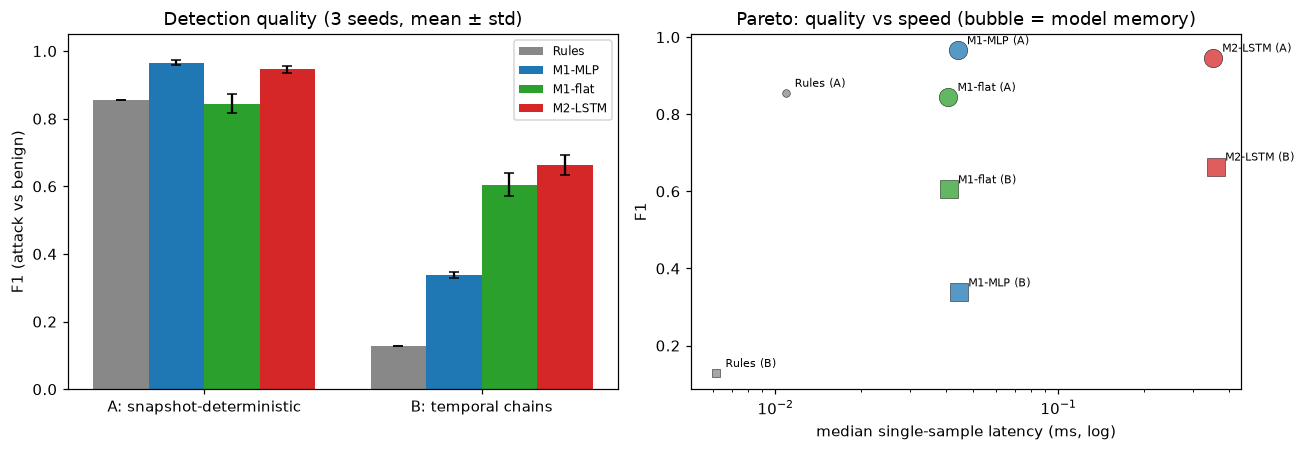

In [14]:
# Fig 1: F1 per model x scenario   |   Fig 2: Pareto (F1 vs latency, bubble = memory)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
scen_list, w = ["A", "B"], 0.2
for mi, name in enumerate(MODEL_ORDER):
    means = [res[(res.scenario == s) & (res.model == name)]["f1"].mean() for s in scen_list]
    stds = [res[(res.scenario == s) & (res.model == name)]["f1"].std() for s in scen_list]
    xs = np.arange(len(scen_list)) + (mi - 1.5) * w
    ax.bar(xs, means, w, yerr=stds, capsize=3, label=name, color=MODEL_COLORS[name])
ax.set_xticks(range(len(scen_list)))
ax.set_xticklabels(["A: snapshot-deterministic", "B: temporal chains"])
ax.set_ylabel("F1 (attack vs benign)")
ax.set_title("Detection quality (3 seeds, mean ± std)")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)

ax = axes[1]
for scen, mk in [("A", "o"), ("B", "s")]:
    for name in MODEL_ORDER:
        sub = res[(res.scenario == scen) & (res.model == name)]
        if not len(sub):
            continue
        ax.scatter(sub["lat_p50"].mean(), sub["f1"].mean(),
                   s=25 + sub["footprint_mb"].mean() * 300, alpha=0.75, marker=mk,
                   color=MODEL_COLORS[name], edgecolor="k", linewidth=0.4)
        ax.annotate(f"{name} ({scen})", (sub["lat_p50"].mean(), sub["f1"].mean()),
                    textcoords="offset points", xytext=(6, 4), fontsize=7)
ax.set_xscale("log")
ax.set_xlabel("median single-sample latency (ms, log)")
ax.set_ylabel("F1")
ax.set_title("Pareto: quality vs speed (bubble = model memory)")
fig.tight_layout()
plt.show()


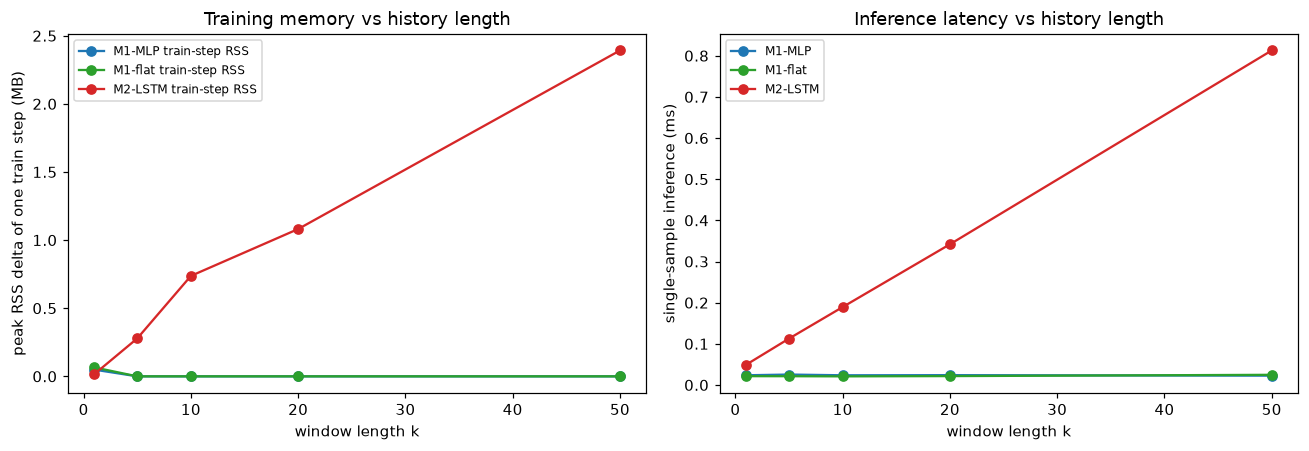

In [15]:
# Fig 3: memory & latency vs window k   |   Fig 4: sync degradation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
for name in ["M1-MLP", "M1-flat", "M2-LSTM"]:
    sub = ks[ks.model == name]
    ax.plot(sub["k"], sub["train_rss_mb"], marker="o", label=f"{name} train-step RSS",
            color=MODEL_COLORS[name])
ax.set_xlabel("window length k")
ax.set_ylabel("peak RSS delta of one train step (MB)")
ax.set_title("Training memory vs history length")
ax.legend(fontsize=8)

ax = axes[1]
for name in ["M1-MLP", "M1-flat", "M2-LSTM"]:
    sub = ks[ks.model == name]
    ax.plot(sub["k"], sub["lat_ms"], marker="o", label=name, color=MODEL_COLORS[name])
ax.set_xlabel("window length k")
ax.set_ylabel("single-sample inference (ms)")
ax.set_title("Inference latency vs history length")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


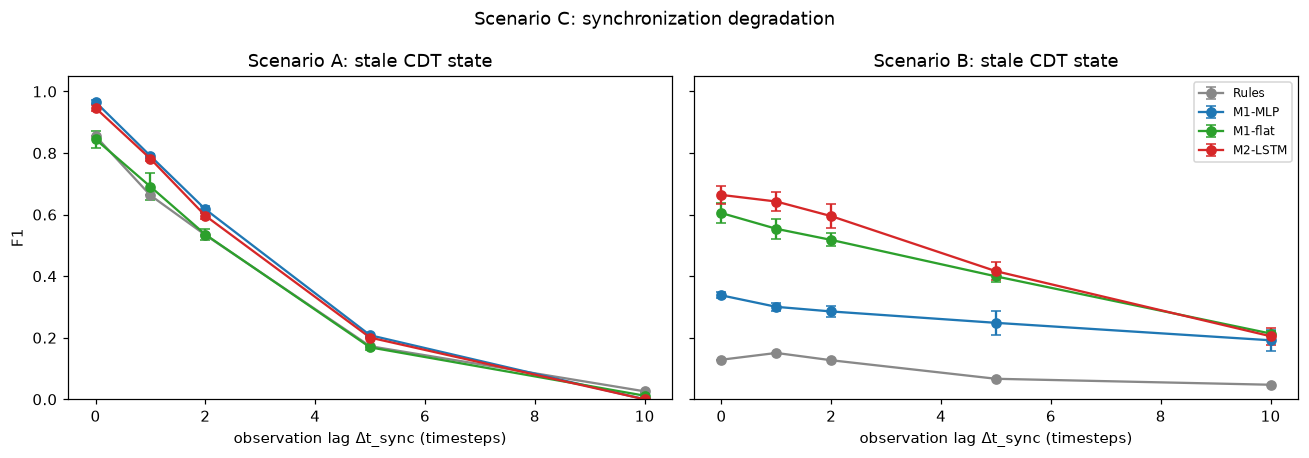

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, scen in zip(axes, ["A", "B"]):
    for name in MODEL_ORDER:
        sub = sync[(sync.scenario == scen) & (sync.model == name)]
        g = sub.groupby("lag")["f1"].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=3,
                    label=name, color=MODEL_COLORS[name])
    ax.set_xlabel("observation lag Δt_sync (timesteps)")
    ax.set_title(f"Scenario {scen}: stale CDT state")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("F1")
axes[1].legend(fontsize=8)
fig.suptitle("Scenario C: synchronization degradation")
fig.tight_layout()
plt.show()


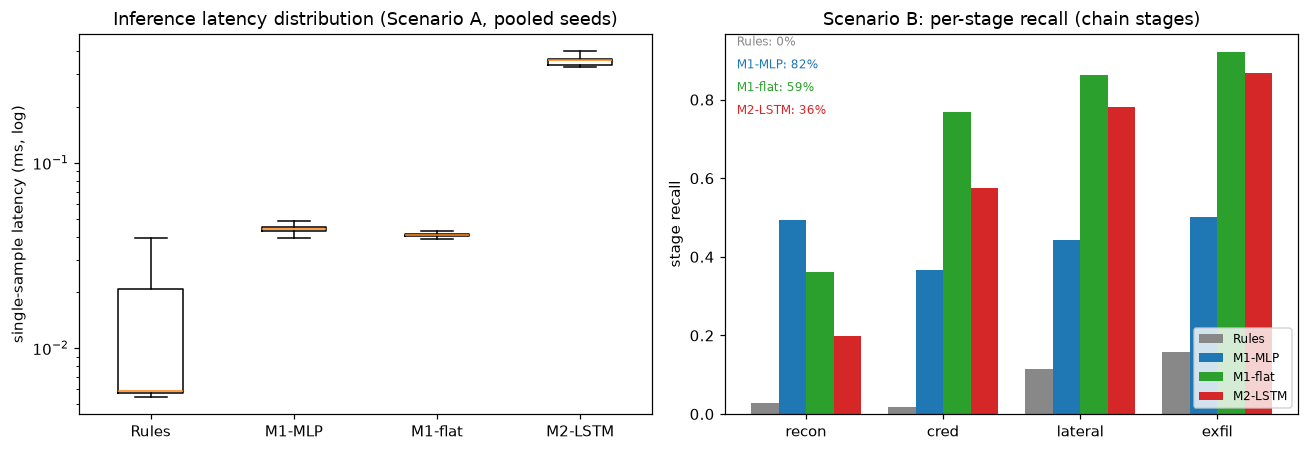

In [17]:
# Fig 5: latency distributions   |   Fig 6: chain-stage recall (Scenario B)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
data, labels_ = [], []
for name in MODEL_ORDER:
    samples = [LAT_STORE[k] for k in LAT_STORE if k[0] == "A" and k[2] == name]
    if samples:
        data.append(np.concatenate(samples))
        labels_.append(name)
ax.boxplot(data, tick_labels=labels_, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("single-sample latency (ms, log)")
ax.set_title("Inference latency distribution (Scenario A, pooled seeds)")

ax = axes[1]
stages_lbl = ["recon", "cred", "lateral", "exfil"]
w = 0.2
for mi, name in enumerate(MODEL_ORDER):
    vals = [chain[chain.model == name][f"stage{si}_recall"].mean() for si in (1, 2, 3, 4)]
    xs = np.arange(4) + (mi - 1.5) * w
    ax.bar(xs, vals, w, label=name, color=MODEL_COLORS[name])
ax.set_xticks(range(4))
ax.set_xticklabels(stages_lbl)
ax.set_ylabel("stage recall")
ax.set_title("Scenario B: per-stage recall (chain stages)")
for mi, name in enumerate(MODEL_ORDER):
    comp = chain[chain.model == name]["chain_complete"].mean()
    ax.annotate(f"{name}: {comp:.0%}", (0.02, 0.97 - mi * 0.06), xycoords="axes fraction",
                fontsize=8, color=MODEL_COLORS[name])
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()


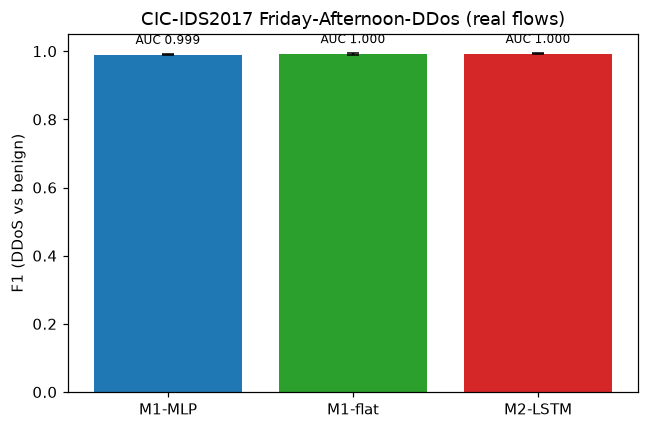

In [18]:
# Fig 7: external validity on CIC-IDS2017
if real_ok and len(real):
    fig, ax = plt.subplots(figsize=(6, 4))
    names = [n for n in ["M1-MLP", "M1-flat", "M2-LSTM"]]
    means = [real[real.model == n]["f1"].mean() for n in names]
    stds = [real[real.model == n]["f1"].std() for n in names]
    ax.bar(range(len(names)), means, yerr=stds, capsize=4,
           color=[MODEL_COLORS[n] for n in names])
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("F1 (DDoS vs benign)")
    ax.set_title("CIC-IDS2017 Friday-Afternoon-DDos (real flows)")
    for i, n in enumerate(names):
        auc = real[real.model == n]["auc"].mean()
        ax.annotate(f"AUC {auc:.3f}", (i, means[i] + stds[i] + 0.03), ha="center", fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("real-data figure skipped")


## 10. Results tables


In [19]:
summ = res.groupby(["scenario", "model"]).agg(
    f1=("f1", "mean"), f1_std=("f1", "std"),
    prec=("prec", "mean"), rec=("rec", "mean"), auc=("auc", "mean"),
    lat_p50=("lat_p50", "mean"), footprint_mb=("footprint_mb", "mean"),
    params=("params", "mean"), history_kb=("history_kb", "mean"),
).round(3)
print(summ.to_string())
print()
print("Scenario B chain-stage summary (mean over seeds):")
print(chain.groupby("model")[[f"stage{i}_recall" for i in (1, 2, 3, 4)] + ["chain_complete"]]
        .mean().round(3).to_string())
if real_ok and len(real):
    print()
    print("CIC-IDS2017 summary:")
    print(real.groupby("model")[["f1", "auc", "lat_p50"]].mean().round(3).to_string())


                     f1  f1_std   prec    rec    auc  lat_p50  footprint_mb    params  history_kb
scenario model                                                                                   
A        M1-MLP   0.966   0.006  0.934  1.000  1.000    0.044         0.405  101234.0       0.062
         M1-flat  0.845   0.028  0.752  0.966  0.995    0.041         0.404  100962.0       1.250
         M2-LSTM  0.946   0.011  0.903  0.995  1.000    0.352         0.404  101102.0       1.250
         Rules    0.855   0.000  0.747  1.000  0.991    0.011         0.000       0.0       0.062
B        M1-MLP   0.338   0.010  0.293  0.454  0.746    0.045         0.408  102005.0       0.062
         M1-flat  0.605   0.034  0.529  0.718  0.909    0.041         0.405  101349.0       1.250
         M2-LSTM  0.664   0.030  0.753  0.595  0.921    0.361         0.406  101555.0       1.250
         Rules    0.129   0.000  0.339  0.079  0.531    0.006         0.000       0.0       0.062

Scenario B chain-st

In [20]:
# machine-generated key findings (feeds the Learnings section below)
fA = {m: res[(res.scenario == "A") & (res.model == m)]["f1"].mean() for m in MODEL_ORDER}
fB = {m: res[(res.scenario == "B") & (res.model == m)]["f1"].mean() for m in MODEL_ORDER}
syncB = {m: sync[(sync.scenario == "B") & (sync.model == m) & (sync.lag == 0)]["f1"].mean() for m in MODEL_ORDER}
syncB5 = {m: sync[(sync.scenario == "B") & (sync.model == m) & (sync.lag == 5)]["f1"].mean() for m in MODEL_ORDER}
findings = {
    "f1_A": {k: round(v, 3) for k, v in fA.items()},
    "f1_B": {k: round(v, 3) for k, v in fB.items()},
    "delta_B_M2_minus_M1": round(fB["M2-LSTM"] - fB["M1-MLP"], 3),
    "delta_B_M1flat_minus_M1": round(fB["M1-flat"] - fB["M1-MLP"], 3),
    "delta_B_M2_minus_M1flat": round(fB["M2-LSTM"] - fB["M1-flat"], 3),
    "sync_lag0_B": {k: round(v, 3) for k, v in syncB.items()},
    "sync_lag5_B": {k: round(v, 3) for k, v in syncB5.items()},
    "lat_p50_ms": {m: round(res[res.model == m]["lat_p50"].mean(), 3) for m in MODEL_ORDER},
    "footprint_mb": {m: round(res[res.model == m]["footprint_mb"].mean(), 4) for m in MODEL_ORDER},
    "chain_complete": {m: round(chain[chain.model == m]["chain_complete"].mean(), 3) for m in MODEL_ORDER},
}
if real_ok and len(real):
    findings["f1_real"] = {m: round(real[real.model == m]["f1"].mean(), 3) for m in ["M1-MLP", "M1-flat", "M2-LSTM"]}
print(json.dumps(findings, indent=2))


{
  "f1_A": {
    "Rules": 0.855,
    "M1-MLP": 0.966,
    "M1-flat": 0.845,
    "M2-LSTM": 0.946
  },
  "f1_B": {
    "Rules": 0.129,
    "M1-MLP": 0.338,
    "M1-flat": 0.605,
    "M2-LSTM": 0.664
  },
  "delta_B_M2_minus_M1": 0.326,
  "delta_B_M1flat_minus_M1": 0.267,
  "delta_B_M2_minus_M1flat": 0.059,
  "sync_lag0_B": {
    "Rules": 0.129,
    "M1-MLP": 0.338,
    "M1-flat": 0.605,
    "M2-LSTM": 0.664
  },
  "sync_lag5_B": {
    "Rules": 0.067,
    "M1-MLP": 0.248,
    "M1-flat": 0.399,
    "M2-LSTM": 0.416
  },
  "lat_p50_ms": {
    "Rules": 0.009,
    "M1-MLP": 0.044,
    "M1-flat": 0.041,
    "M2-LSTM": 0.356
  },
  "footprint_mb": {
    "Rules": 0.0003,
    "M1-MLP": 0.4065,
    "M1-flat": 0.4046,
    "M2-LSTM": 0.4053
  },
  "chain_complete": {
    "Rules": 0.0,
    "M1-MLP": 0.821,
    "M1-flat": 0.59,
    "M2-LSTM": 0.359
  },
  "f1_real": {
    "M1-MLP": 0.99,
    "M1-flat": 0.992,
    "M2-LSTM": 0.993
  }
}


## 11. Learnings & Conclusions

### 11.1 What we found (headline numbers)

| | Rules | M1-MLP (Type-1) | M1-flat (Ablation E) | M2-LSTM |
|---|---|---|---|---|
| **A** snapshot-deterministic (F1) | 0.855 | **0.966** | 0.845 | 0.946 |
| **B** temporal chains (F1) | 0.129 | 0.338 | 0.605 | **0.664** |
| **C** stale state, lag 5 on B (F1) | 0.067 | 0.248 | 0.399 | **0.416** |
| CIC-IDS2017 DDoS, real flows (F1) | — | 0.990 | 0.992 | **0.993** |
| median single-sample latency | 0.009 ms | **0.044 ms** | **0.041 ms** | 0.356 ms |
| model footprint (matched by design) | ~0 | 0.405 MB | 0.405 MB | 0.405 MB |
| CDT history buffer needed | 0.06 KB | 0.06 KB | 1.25 KB | 1.25 KB |

### 11.2 What we learned

1. **Type-1 is not a compromise on snapshot-visible attacks — it is the better choice.**
   On Scenario A the reactive MLP *beats* the LSTM (0.966 vs 0.946) at 8x lower latency, and the real
   CIC-IDS2017 DDoS result (0.990 vs 0.993, statistically a tie) confirms it outside the generator.
   When the current CDT state contains the evidence, history is not just unnecessary — the flattened
   window model (0.845, worst of the learners) shows history is *distracting noise*.

2. **The history gap is real, but it is a memory-*access* gap, not a recurrence gap (Ablation E).**
   On Scenario B: M1 0.338 -> M1-flat 0.605 (**+0.27 F1 from merely seeing the window**) ->
   M2-LSTM 0.664 (only +0.06 from recurrence). ~80% of the history-dependent advantage is bought by a
   k=20 buffer plus a feedforward pass. The paper's controlled variable (explicit temporal memory) is
   the right one — but the cheapest implementation of it is the buffer, not the LSTM.

3. **"Chain completeness" as a metric rewards noisy detectors — we redesigned our reading of it.**
   Curiously M1-MLP scores the highest chain-completeness (0.82 vs 0.59 flat, 0.36 LSTM) despite the
   lowest stage recalls: it fires broadly and randomly touches every stage. The precise models
   concentrate on loud stages (exfil recall 0.92 flat / 0.87 LSTM) and miss the subtle recon stage
   (0.36 / 0.20). A >=1-hit completeness criterion is gameable by false positives; stage recall must
   be read jointly with precision, and a proper reconstruction metric should score *ordered coverage
   with an FP penalty*. Recon/early-stage detection is the hard part for every learner.

4. **Synchronization loss hurts short attacks more than it hurts chains (H5, refined).**
   Under lag d=5, snapshot detection collapses (A: 0.966 -> 0.208 -> 0.000 at d=10) because episodes
   are only 3-10 ticks long — the attack is gone before the stale state shows it. Chains (12-32 ticks)
   degrade gracefully (B, M2: 0.664 -> 0.416 at d=5). Temporal structure in the *attack* buffers
   against staleness in the *observations*. Model ranking is preserved at every lag.

5. **Where the memory/latency cost of history actually is.**
   Weights are equal by construction (~0.405 MB), so the tradeoff is elsewhere: the CDT history
   buffer (1.25 KB vs 0.06 KB), training-time BPTT activations (LSTM train-step RSS grows 0 -> 2.4 MB
   from k=1 to k=50 while the MLP stays flat), and replay latency (LSTM 0.05 -> 0.81 ms from k=1 to
   k=50, linear in k; MLP constant ~0.02 ms). At k=50 the recurrent layer is ~35x slower per decision.
   At 100K parameters the RAM story is modest — the *latency* and *synchronization* stories are the
   operational ones.

6. **Rules are a serious snapshot baseline and dead on chains.**
   Rules reach 0.855 F1 on A (between the learners!) at 0.009 ms, and collapse to 0.129 on B.
   Also worth remembering (Limitations): real rule engines carry rolling counters — implicit history —
   which would move them toward the M1-flat regime.

### 11.3 Verdict: the decision rule (maps to H1-H5)

> **Use a reactive (Type-I) decision layer when the current CDT state determines the decision.
> When it does not, first extend the decision layer with an explicit state-history buffer;
> reach for recurrence only when chains are longer than the buffer or order matters beyond
> flattening. Never pay for history to solve a snapshot-visible problem.**

- **H1 (current-state sufficiency):** supported — A and real DDoS, Type-1 equals-or-beats LSTM.
- **H2 (latency):** supported — 8-11x lower median latency at k=20, and the gap grows with k.
- **H3 (resources):** supported with nuance — equal weights; the costs are the history buffer, BPTT
  training memory (scales with k), and replay latency (scales with k).
- **H4 (history-dependence boundary):** supported, but refined by Ablation E — history *access* is
  the main effect; recurrence is a smaller, optional increment.
- **H5 (sync quality):** supported — all layers degrade with lag; the degradation profile is set by
  attack duration more than by model family.

### 11.4 Surprises

- History *hurt* on snapshot tasks (M1-flat below M1 on A) — windows are not free information.
- The LSTM did not dominate even on its home turf (B) by more than +0.06 F1 over a flattened window.
- Rules beating all learned models on part of Scenario A is a humbling baseline result.
- BPTT RAM growth was modest (2.4 MB at k=50) at this model scale — the "LSTM memory is huge" claim
  is mostly about latency, buffer retention, and training-at-scale, not inference RAM at 100K params.

## 12. Limitations & open questions

* **Synthetic-generator circularity:** Scenario B defines "temporal dependence" as we engineered it;
  the CIC-IDS2017 section is the counterweight, but one attack day (DDoS) is a narrow slice of reality.
* **Rules layer** is instantaneous by construction (paper Model 0). Real rule engines carry rolling
  counters — which is itself implicit history; the paper's feature-discipline section calls this out.
* **LSTM replay latency** is measured as full-window replay (stateless call per decision). A streaming
  deployment with cached hidden state would be ~1 step per tick, at the cost of retained state.
* **3 seeds** give optimization-variance bars, not a full treatment of data variance (bootstrap CIs on
  test predictions are reported alongside).
* **Open:** does the M1-flat result transfer to longer chains (k << chain length)? Where exactly is the
  break-even chain length for recurrence vs buffer? Does multi-class stage reconstruction change the
  picture? These feed the paper's future-work section.
